<a href="https://colab.research.google.com/github/TejasDharmale/Neural_computation/blob/main/20261102_SWK_Neural_computation_assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>  

# Neural computation - Workgroup Assignment 1
<br/>
<br/>
    
<center>
Radboud University


<center>
September 2024


<center>
Sander Keemink
    



## Instructions
To finish this assignment, answer the below questions *in this notebook*, and upload the result on brightspace as your assignment submission. Clearly indicate your own additions to the notebook.

You can work together, but do not copy each other's code -- this is considered plagiarism!

When asked to mathematically show something, use latex to show the steps.

When asked to plot something, use the plotting toolbox of your choice to do so. (we took the liberty of importing matplotlib)

Topics 1-3 (and half today's grade) are meant to give you some practice with the core skills required. The final topic (the other half of the grade) will take more time, and is the core assignment.

At the end we will put example exam questions you might be asked on the exam, to give you a better idea of what skills learned during this assignment will be used there.

### Basic imports

In [2]:
# the only two python modules you will need for this tutorial are numpy and matplotlib
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

### Topic 1: Linear 1D system and fixed points (0.5 points)
Consider the following neuron model

$\dot{r} = f(r),$

where $r$ is the firing rate of a neuron, and it's activation function is given by
$f(r) = (w-1)r+I,$

where w is a self connection, and I some external input.

($\dot{r}$ is short hand for $\frac{dr}{dt}$)

(A) For $w=-0.5$ and $I=0$ plot the derivative as a function of the firing rate $r$. Mathematically show what the fixed point is, and determine its stability, and explain by referring to the graph. (0.25 points)

(B) Do the same for $w = 1.5$ and $I=-2$. (0.25 points)


###Answers

##A] **My answer: Topic 1 (A)**

$$
\begin{aligned}
&\textbf{Given: } w = -0.5,\; I = 0 \\[6pt]
&f(r) = (w-1)\,r + I = (-0.5-1)\,r + 0 = -1.5\,r \\[10pt]
&\textbf{Fixed point: } \dot r = 0 \\
&f(r^*) = -1.5\,r^* = 0 \;\Longrightarrow\; r^* = 0 \\[10pt]
&\textbf{Stability: } \\
&f'(r) = \frac{d}{dr}\left(-1.5\,r\right) = -1.5 \\
&f'(r^*) = -1.5 < 0 \;\Longrightarrow\; r^* = 0 \text{ is stable} \\[10pt]
&\textbf{Linearisation: } \delta = r - r^* \\
&\dot\delta = f'(r^*)\,\delta = -1.5\,\delta \;\Longrightarrow\; \delta(t) = \delta_0\, e^{-1.5\,t} \xrightarrow{t\to\infty} 0
\end{aligned}
$$

**Interpretation of the graph.** The graph intersects $\dot r=0$ at $r=0$ with a negative slope. When $r<0$, then $\dot r>0$, and $r$ is growing to zero. When $r>0$, then $\dot r<0$, and $r$ is decaying to zero. Therefore, the flow is directed to the fixed point on both sides.

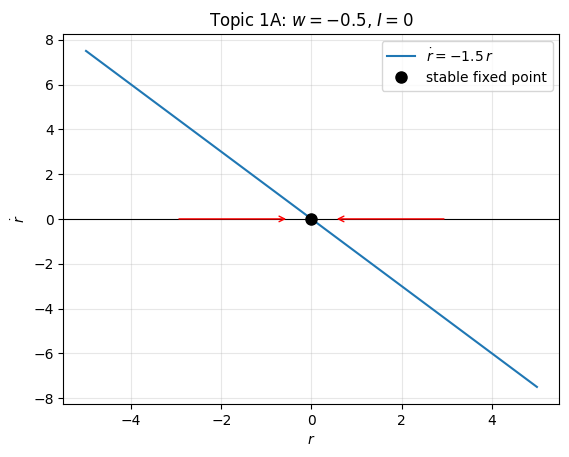

In [3]:
import numpy as np
import matplotlib.pyplot as plt

w, I = -0.5, 0
r = np.linspace(-5, 5, 200)
drdt = (w - 1) * r + I
r_star = -I / (w - 1)

plt.plot(r, drdt, label=r'$\dot r = -1.5\,r$')
plt.axhline(0, color='k', lw=0.8)
plt.plot(r_star, 0, 'o', color='k', markersize=8, label='stable fixed point')
plt.annotate('', xy=(-0.5, 0), xytext=(-3, 0), arrowprops=dict(arrowstyle='->', color='red'))
plt.annotate('', xy=(0.5, 0), xytext=(3, 0), arrowprops=dict(arrowstyle='->', color='red'))

plt.xlabel('$r$')
plt.ylabel(r'$\dot r$')
plt.title('Topic 1A: $w=-0.5$, $I=0$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**My answer: Topic 1 (B)**

$$
\begin{aligned}
&\textbf{Given: } w = 1.5,\; I = -2 \\[6pt]
&f(r) = (w-1)\,r + I = (1.5-1)\,r - 2 = 0.5\,r - 2 \\[10pt]
&\textbf{Fixed point: } \dot r = 0 \\
&f(r^*) = 0.5\,r^* - 2 = 0 \;\Longrightarrow\; r^* = \frac{2}{0.5} = 4 \\[10pt]
&\textbf{Stability: } \\
&f'(r) = \frac{d}{dr}\left(0.5\,r - 2\right) = 0.5 \\
&f'(r^*) = 0.5 > 0 \;\Longrightarrow\; r^* = 4 \text{ is unstable} \\[10pt]
&\textbf{Linearisation: } \delta = r - r^* \\
&\dot\delta = f'(r^*)\,\delta = 0.5\,\delta \;\Longrightarrow\; \delta(t) = \delta_0\, e^{0.5\,t} \xrightarrow{t\to\infty} \pm\infty
\end{aligned}
$$

**Analysis of the graph.** The curve intersects $\dot r = 0$ at $r = 4$ with positive slope. When $r < 4$, $\dot r < 0$, which means that $r$ moves away from 4. If $r > 4$, then $\dot r > 0$ and hence $r$ again moves away from 4. Thus, the flow moves away from the fixed point in both cases and hence a small disturbance will grow making the fixed point unstable. Informally, the self connectivity $w = 1.5$ dominates over the decay and thus any deviation is amplified.

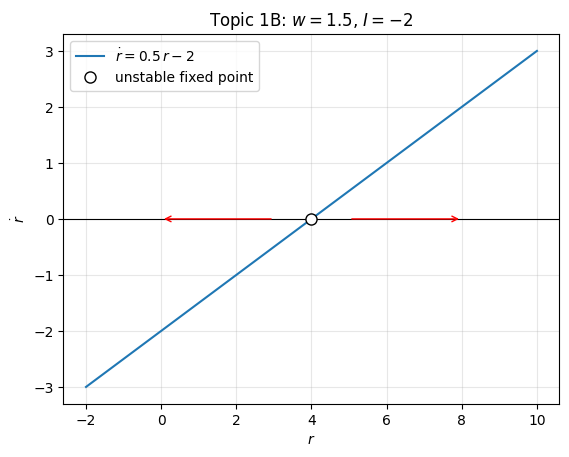

In [4]:
w, I = 1.5, -2
r = np.linspace(-2, 10, 200)
drdt = (w - 1) * r + I
r_star = -I / (w - 1)

plt.plot(r, drdt, label=r'$\dot r = 0.5\,r - 2$')
plt.axhline(0, color='k', lw=0.8)
plt.plot(r_star, 0, 'o', markerfacecolor='white', markeredgecolor='k',
         markersize=8, label='unstable fixed point')
plt.annotate('', xy=(0, 0), xytext=(3, 0), arrowprops=dict(arrowstyle='->', color='red'))
plt.annotate('', xy=(8, 0), xytext=(5, 0), arrowprops=dict(arrowstyle='->', color='red'))

plt.xlabel('$r$')
plt.ylabel(r'$\dot r$')
plt.title('Topic 1B: $w=1.5$, $I=-2$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Topic 2: Integration methods (1 point)
Many differential equations are hard to solve analytically, but are fairly easy to simulate through step-wise integration methods. In this exercise we will explore these.

The Euler method is the simplest and surprisingly effective (https://en.wikipedia.org/wiki/Euler_method). We have implemented it for you below:

In [5]:
# a simple euler-solver
def euler_solve(f, x0, par, dt, nT):
    '''Simulates the system of differential equations specified by dx/dt = f(x, par), using forward Euler.

    Dimensioality of system will below be given by K. (i.e. for 2D systems K=2)

    Parameters
    ----------
    f : function
        Function of form f(x, par). Should output array of length K.
    x0 : array, shape
        Starting values. Should be list or array of length K.
    par : unknown
        Whatever parameters go into f (can be single variable, or a list, etc.)
    dt : float
        Timestep size
    nT : int
        Number of timesteps

    Output
    ------
    array
        Simulated values, of shape (K, nT).
    '''
    # preamble
    nS = len(x0) # nr of equations/signals
    xs = np.zeros((nS, nT)) # predefined output
    xs[:, 0] = x0

    # loop over time
    for i in range(nT-1):
        xs[:, i+1] = xs[:, i] + dt*f(xs[:, i], par)

    # return
    return xs

#### Example implementation for $\dot{r} =-s r$

In [6]:
# Parameters
s = 1
par = [s]
f = lambda x, par: -par[0]*x
r0 = np.array([1])
dt = 1e-2
nT = 100

# simulate
r_simulated = euler_solve(f, r0, par, dt, nT)

#### Questions
(A) Use the Euler method to solve the systems from topic 1 and confirm your fixed-point predictions. (0.5 points)

(B) Implement similar solvers for the improved Euler method (https://en.wikipedia.org/wiki/Heun's_method) and the fourth-order Runge-Kutta method (https://en.wikipedia.org/wiki/Runge%E2%80%93Kutta_methods). Note that our functions have no explicit time dependence. The analytical solution to the differential equation is $r(t) = r_0 e^{(w-1) t}$. For different timesteps and starting conditions, compare how well each method (Euler, improved Euler, and Runge-Kutta) matches the analytical solution. (0.5 points)

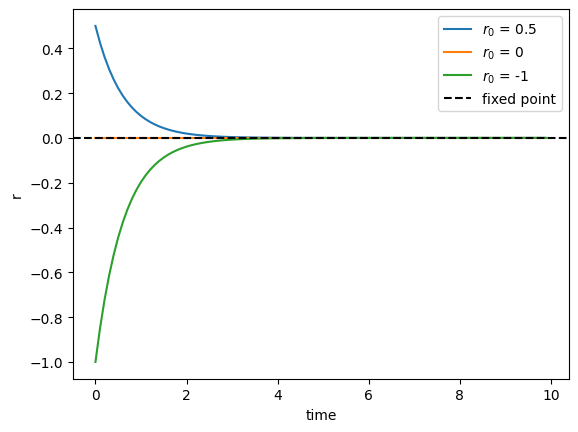

In [7]:
# My answer: Topic 2 (A), system A
w, I = -0.5, 0
par = [w, I]
f = lambda x, par: (par[0] - 1) * x + par[1]
dt = 0.1
nT = 100
t = np.arange(nT) * dt

for r0 in [0.5, 0, -1]:
    r_sim = euler_solve(f, np.array([r0]), par, dt, nT)
    plt.plot(t, r_sim[0], label=f'$r_0$ = {r0}')

plt.axhline(y=0, ls='--', color='k', label='fixed point')
plt.xlabel('time'); plt.ylabel('r'); plt.legend(); plt.show()

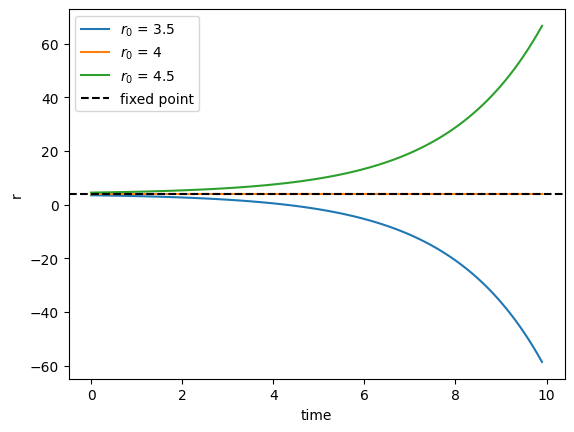

In [8]:
# My answer: Topic 2 (A), system B
w, I = 1.5, -2
par = [w, I]
f = lambda x, par: (par[0] - 1) * x + par[1]
dt = 0.1
nT = 100
t = np.arange(nT) * dt

for r0 in [3.5, 4, 4.5]:
    r_sim = euler_solve(f, np.array([r0]), par, dt, nT)
    plt.plot(t, r_sim[0], label=f'$r_0$ = {r0}')

plt.axhline(y=4, ls='--', color='k', label='fixed point')
plt.xlabel('time'); plt.ylabel('r'); plt.legend(); plt.show()

In [9]:
#MY Interpretation:
# System A (w = -0.5, I = 0): r* = 0, slope -1.5 < 0. All runs end up at 0, thus it is a stable fixed point.
# System B (w = 1.5, I = -2): r* = 4, slope 0.5 > 0. r0 = 4 doesn’t change; all nearby runs diverge from it, hence it’s an unstable fixed point.
# Simulations support Topic 1 predictions.

In [10]:
# My answer: Topic 2 (B), solvers

def heun_solve(f, x0, par, dt, nT):
    '''Improved Euler (Heun): average the slope at the start and at a trial Euler step.'''
    nS = len(x0)
    xs = np.zeros((nS, nT))
    xs[:, 0] = x0
    for i in range(nT-1):
        k1 = f(xs[:, i], par)
        k2 = f(xs[:, i] + dt*k1, par)
        xs[:, i+1] = xs[:, i] + dt/2*(k1 + k2)
    return xs


def rk4_solve(f, x0, par, dt, nT):
    '''Fourth order Runge Kutta: weighted average of four slopes.'''
    nS = len(x0)
    xs = np.zeros((nS, nT))
    xs[:, 0] = x0
    for i in range(nT-1):
        x = xs[:, i]
        k1 = f(x, par)
        k2 = f(x + dt/2*k1, par)
        k3 = f(x + dt/2*k2, par)
        k4 = f(x + dt*k3, par)
        xs[:, i+1] = x + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    return xs

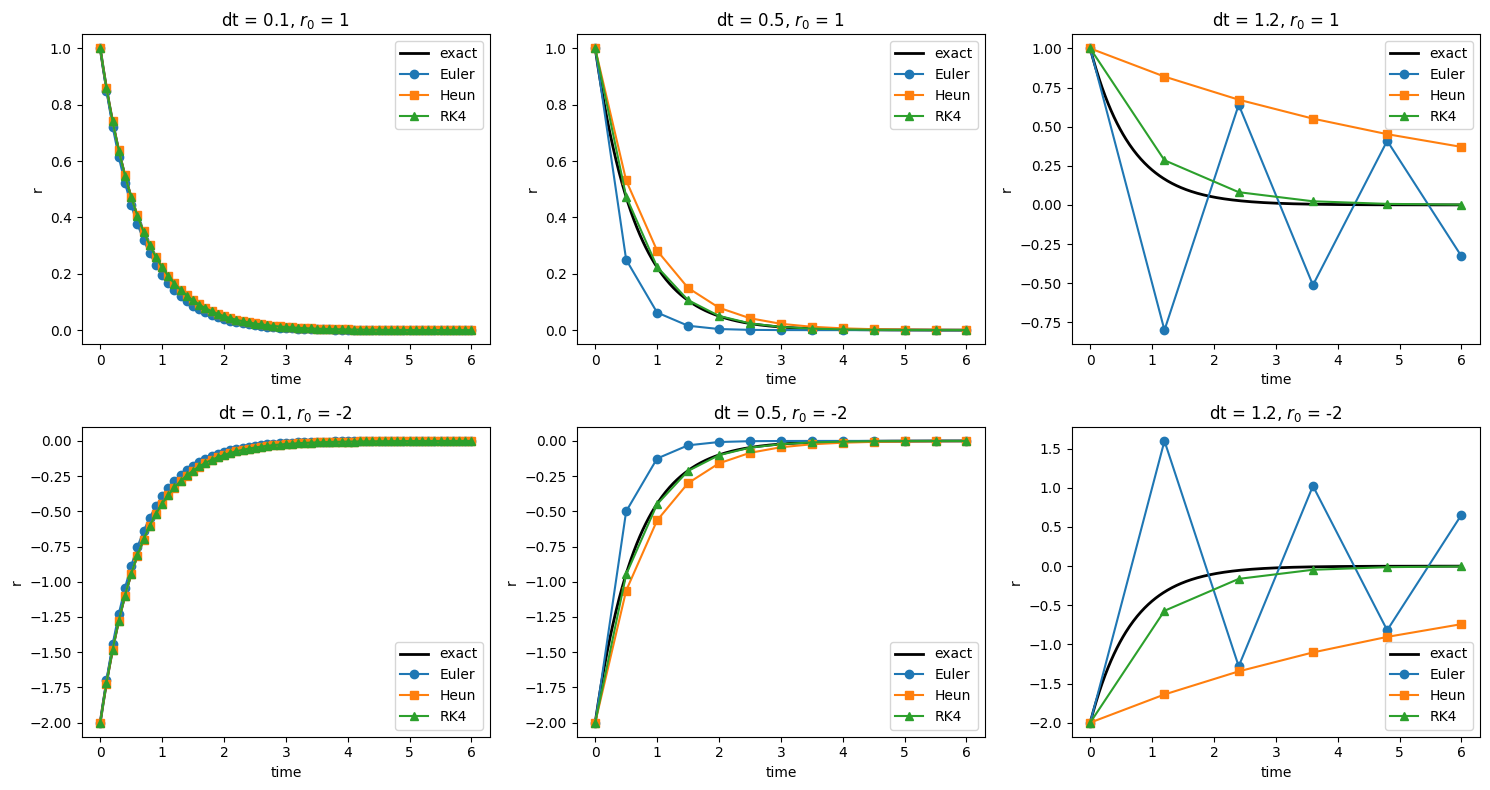

In [11]:
#  My answer: Topic 2 (B), comparison on system A =
w, I = -0.5, 0
par = [w, I]
f = lambda x, par: (par[0] - 1) * x + par[1]
T = 6

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, dt in enumerate([0.1, 0.5, 1.2]):
    for row, r0 in enumerate([1, -2]):
        nT = int(T / dt) + 1
        t = np.arange(nT) * dt
        t_fine = np.linspace(0, T, 500)
        exact = r0 * np.exp((w - 1) * t_fine)

        ax = axes[row, col]
        ax.plot(t_fine, exact, 'k', lw=2, label='exact')
        ax.plot(t, euler_solve(f, np.array([r0]), par, dt, nT)[0], 'o-', label='Euler')
        ax.plot(t, heun_solve(f, np.array([r0]), par, dt, nT)[0], 's-', label='Heun')
        ax.plot(t, rk4_solve(f, np.array([r0]), par, dt, nT)[0], '^-', label='RK4')
        ax.set_title(f'dt = {dt}, $r_0$ = {r0}')
        ax.set_xlabel('time'); ax.set_ylabel('r')
        ax.legend()

plt.tight_layout()
plt.show()

**My answer: Topic 2 (B), comparison**

The provided analytical solution $r(t) = r_0 e^{(w-1)t}$ is only applicable to $I = 0$, therefore the comparison is carried out for system A ($w = -0.5$, hence $\lambda = w - 1 = -1.5$).

Since this is a linear system, all three methods multiply $r$ by a constant at each step. With $h = \lambda\,\Delta t$:

| | Euler $1 + h$ | Heun $1 + h + \frac{h^2}{2}$ | RK4 $1 + h + \frac{h^2}{2} + \frac{h^3}{6} + \frac{h^4}{24}$ | Exact $e^{h}$ |
|---|---|---|---|---|
| $\Delta t = 0.1$ | 0.850 | 0.861 | 0.8607 | 0.8607 |
| $\Delta t = 0.5$ | 0.250 | 0.531 | 0.474 | 0.472 |
| $\Delta t = 1.2$ | $-0.800$ | 0.820 | 0.285 | 0.165 |

**Comments on the plots:**
* For small $\Delta t = 0.1$, all three methods follow the exact plot closely; RK4 is nearly identical to the exact curve.
* For $\Delta t = 0.5$, Euler converges too rapidly, Heun too slowly, and RK4 is still almost exact.
* For large $\Delta t = 1.2$, Euler's coefficient becomes negative and hence oscillates wildly due to overshooting (artificial behavior of the numerical method, the exact solution doesn't oscillate); Heun decays way too slowly and RK4 follows the exact solution better than the other two but still not exactly.
* The initial value $r_0$ only rescales the plot as the system is linear and therefore does not affect the accuracy of the method.

**Conclusion:** the order of the approximation method plays an important role; the errors for Euler, Heun, and RK4 are proportional to $\Delta t$, $\Delta t^2$, and $\Delta t^4$, respectively.

### Topic 3: Linear 2D systems (1.5 points)

We provide below a function for plotting phaseplanes and nullclines.


In [12]:
def phaseplane_2D(f, par, xs_nullclines, xs_quiver=None, add_vectors=False, labels=['x1', 'x2']):
    '''Plots the phaseplane in 2D.

    Parameters
    ----------
    f : function
        Derivative function, of form f(x, par)
    par : unknown
        Whatever parameters the f function needs
    xs_nullclines : array
        Values at which calculate hte nullclines
    xs_quiver : array
        Values at which to plot the derivative vectors (only necessary if add_vectors is True)
    add_vectors : bool, true by default
        Whether to plot the vector fields
    labels : list of strings
        Optional axis name changes (default: ['x1', 'x2'])
    '''
    # first calculate nullclines
    # get number of grid points
    n_grid = len(xs_nullclines)

    # derivatives at each of the points
    x1_grid = np.array([[x1 for x1 in xs_nullclines] for x2 in xs_nullclines])
    x2_grid = np.array([[x2 for x1 in xs_nullclines] for x2 in xs_nullclines])
    f_grid = np.array([[f(np.array([x1, x2]), par) for x1 in xs_nullclines] for x2 in xs_nullclines])

    # plot nullclines
    plt.contour(x1_grid, x2_grid, f_grid[:, :, 0], 0, colors='r')
    plt.contour(x1_grid, x2_grid, f_grid[:, :, 1], 0, colors='b')

    # then plot quivers
    if add_vectors:
        # get number of grid points
        n_grid = len(xs_quiver)

        # derivatives at each of the points
        x1_grid = np.array([[x1 for x1 in xs_quiver] for x2 in xs_quiver])
        x2_grid = np.array([[x2 for x1 in xs_quiver] for x2 in xs_quiver])
        f_grid = np.array([[f(np.array([x1, x2]), par) for x1 in xs_quiver] for x2 in xs_quiver])

        U, V = f_grid[:, :, 0], f_grid[:, :, 1]
        plt.quiver(xs_quiver, xs_quiver, U, V)

    # add labels
    plt.xlabel(labels[0], fontsize=14)
    plt.ylabel(labels[1], fontsize=14)

Consider a small network of two coupled neurons, described as
$\dot{\mathbf r} = \mathbf A \mathbf r,$

where $\mathbf r = [r_1, r_2]^\top$, and $\mathbf A = \begin{bmatrix}
a & b \\
c & d
\end{bmatrix}$.

Here is an example implementation of the ```phaseplane_2D``` function for $\mathbf A = \begin{bmatrix}
-1 & 0 \\
0 & -1
\end{bmatrix}$.


<function matplotlib.pyplot.show(close=None, block=None)>

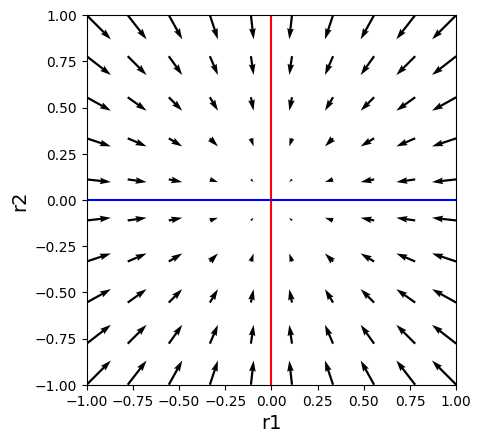

In [13]:
# Parameters
a = -1
b = 0
c = 0
d = -1
A = np.array([[a, b], [c, d]])

# group parameters
par = [A]

# differential equation
f = lambda r, par: par[0]@r

# plot phase plane
n_grid_quiver = 10 # how many points to sample for vector field
rs_quiver = np.linspace(-1, 1, n_grid_quiver)

n_grid_nullclines = 100 # how many points to sample for finding nullclines
rs_nullclines = np.linspace(-1, 1, n_grid_nullclines)

# plot phaseplot
phaseplane_2D(f, par, rs_nullclines, rs_quiver, add_vectors=True, labels=['r1', 'r2'])
plt.axis('scaled')
plt.show

#### Questions

We have uploaded the Dynamical Systems in Neuroscience textbook. Study chapters 4.2.2-4.2.5.

(A) In terms of neural connectivity, describe what the elements of $\mathbf A$ represent. (0.25 points)

(B) For $\mathbf A = \begin{bmatrix}
-1 & 0 \\
0 & 1
\end{bmatrix}$ find the fixed point of this system, the local eigenvalues and eigenvectors mathematically, and verify neumerically (e.g. with np.linalg.eig() ). Based on the results, classify the fixed point or points. Describe how the neural activities will behave near the fixed point. (0.5 points)

(C) Same as (A), but for $\mathbf A = \begin{bmatrix}
-1 & 2 \\
-2 & -1
\end{bmatrix}$. (0.5 points)

(D) Using the provided ```phaseplane_2D()``` function, plot the phase planes for the systems from A+B. Simulate the systems from A+B, and confirm your predictions from A+B. (0.25 points)


**My answer: Topic 3 (A)**

$$
\dot r_1 = a\,r_1 + b\,r_2, \qquad \dot r_2 = c\,r_1 + d\,r_2
$$

* $a$: effective self connection of neuron 1, i.e. its recurrent self weight combined with its natural decay (like $w-1$ in Topic 1). Negative means activity decays, positive means it self amplifies.
* $d$: the same for neuron 2.
* $b$: connection **from neuron 2 to neuron 1**: how much $r_2$ changes the rate of change of $r_1$.
* $c$: connection **from neuron 1 to neuron 2**.

Positive off diagonal elements are excitatory connections, negative ones are inhibitory. If $b = c = 0$ the neurons are uncoupled and each behaves like the 1D system from Topic 1.

**My answer: Topic 3 (B)**,
$A = \begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix}$

**Fixed point.** Set $\dot{\mathbf r} = A\mathbf r = \mathbf 0$:

$$
\begin{aligned}
-r_1 &= 0 \;\Rightarrow\; r_1 = 0 \\
r_2 &= 0
\end{aligned}
\qquad\Rightarrow\qquad \mathbf r^* = (0, 0)
$$

Since $\det A = -1 \neq 0$, this is the only fixed point.

**Eigenvalues.**

$$
\det(A - \lambda I) = (-1-\lambda)(1-\lambda) = 0 \;\Rightarrow\; \lambda_1 = -1,\; \lambda_2 = 1
$$

**Eigenvectors.**

$$
\begin{aligned}
\lambda_1 = -1: \quad (A + I)\mathbf v = \begin{bmatrix} 0 & 0 \\ 0 & 2 \end{bmatrix}\mathbf v = \mathbf 0 &\;\Rightarrow\; \mathbf v_1 = \begin{bmatrix} 1 \\ 0 \end{bmatrix} \\
\lambda_2 = 1: \quad (A - I)\mathbf v = \begin{bmatrix} -2 & 0 \\ 0 & 0 \end{bmatrix}\mathbf v = \mathbf 0 &\;\Rightarrow\; \mathbf v_2 = \begin{bmatrix} 0 \\ 1 \end{bmatrix}
\end{aligned}
$$

**Classification.** The eigenvalues are real with opposite signs, so the origin is a **saddle point** (unstable).

**Behaviour near the fixed point.** The general solution is

$$
\mathbf r(t) = c_1 e^{-t}\begin{bmatrix} 1 \\ 0 \end{bmatrix} + c_2 e^{t}\begin{bmatrix} 0 \\ 1 \end{bmatrix}
$$

The neurons are uncoupled. Activity of neuron 1 decays back to 0 (stable direction along $r_1$), while any perturbation of neuron 2 grows exponentially (unstable direction along $r_2$). Only states exactly on the $r_1$ axis ($r_2 = 0$) return to the origin; any small nonzero $r_2$ makes the system run away along the $r_2$ direction.

In [14]:
#My answer: Topic 3 (B)
A_B = np.array([[-1, 0], [0, 1]])
eigvals_B, eigvecs_B = np.linalg.eig(A_B)
print('Eigenvalues:', eigvals_B)
print('Eigenvectors (columns):\n', eigvecs_B)



Eigenvalues: [-1.  1.]
Eigenvectors (columns):
 [[1. 0.]
 [0. 1.]]


**My answer: Topic 3 (C)**, $A = \begin{bmatrix} -1 & 2 \\ -2 & -1 \end{bmatrix}$

**Fixed point.**

$$
\begin{aligned}
-r_1 + 2r_2 &= 0 \\
-2r_1 - r_2 &= 0
\end{aligned}
\qquad \det A = (-1)(-1) - (2)(-2) = 5 \neq 0 \;\Rightarrow\; \mathbf r^* = (0, 0) \text{ is the only fixed point}
$$

**Eigenvalues.**

$$
\begin{aligned}
\det(A - \lambda I) &= (-1-\lambda)^2 + 4 = 0 \\
(\lambda + 1)^2 &= -4 \\
\lambda_{1,2} &= -1 \pm 2i
\end{aligned}
$$

**Eigenvectors.**

$$
\lambda_1 = -1 + 2i: \quad (A - \lambda_1 I)\mathbf v = \begin{bmatrix} -2i & 2 \\ -2 & -2i \end{bmatrix}\mathbf v = \mathbf 0
\;\Rightarrow\; -2i\,v_1 + 2v_2 = 0 \;\Rightarrow\; \mathbf v_1 = \begin{bmatrix} 1 \\ i \end{bmatrix}
$$

$$
\lambda_2 = -1 - 2i: \quad \mathbf v_2 = \overline{\mathbf v_1} = \begin{bmatrix} 1 \\ -i \end{bmatrix}
$$

**Classification.** The eigenvalues are a complex conjugate pair with negative real part ($\text{Re}\,\lambda = -1$), so the origin is a **stable focus (stable spiral)**.

**Behaviour near the fixed point.** The real part gives exponential decay $e^{-t}$, the imaginary part gives rotation with angular frequency $\omega = 2$ (period $T = 2\pi/2 = \pi$). The real solution is

$$
\mathbf r(t) = e^{-t}\begin{bmatrix} \alpha\cos 2t + \beta\sin 2t \\ -\alpha\sin 2t + \beta\cos 2t \end{bmatrix}
$$

So both neurons show **damped oscillations**, a quarter cycle out of phase with each other, spiralling into the origin. In network terms: neuron 2 excites neuron 1 ($b = 2$) while neuron 1 inhibits neuron 2 ($c = -2$). This excitatory inhibitory loop creates the oscillation, and the negative self terms ($a = d = -1$) damp it.

In [15]:
# My answer: Topic 3 (C)
A_C = np.array([[-1, 2], [-2, -1]])
eigvals_C, eigvecs_C = np.linalg.eig(A_C)
print('Eigenvalues:', eigvals_C)
print('Eigenvectors (columns):\n', eigvecs_C)

Eigenvalues: [-1.+2.j -1.-2.j]
Eigenvectors (columns):
 [[0.        -0.70710678j 0.        +0.70710678j]
 [0.70710678+0.j         0.70710678-0.j        ]]


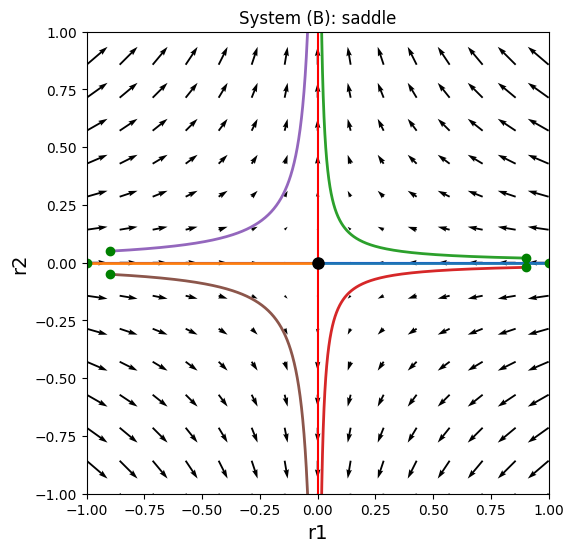

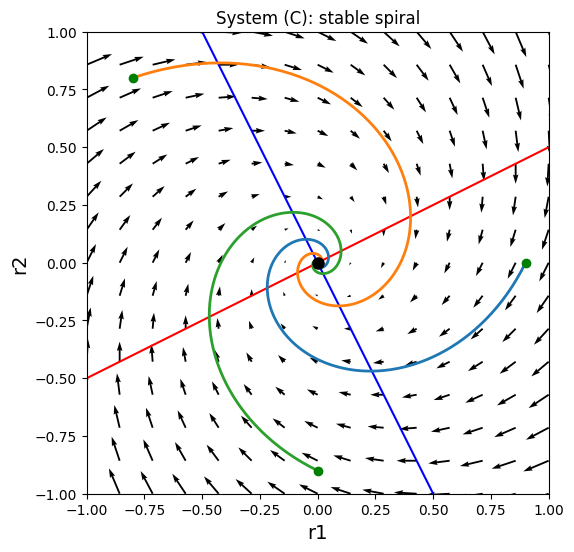

In [21]:
# My answer: Topic 3 (D)
f_lin = lambda r, par: par[0] @ r
def plot_system(A, title, r0_list, dt=0.01, nT=600, lim=1):
    par = [A]
    plt.figure(figsize=(6, 6))
    phaseplane_2D(f_lin, par, np.linspace(-lim, lim, 100), np.linspace(-lim, lim, 15),
                  add_vectors=True, labels=['r1', 'r2'])
    for r0 in r0_list:
        traj = euler_solve(f_lin, np.array(r0, dtype=float), par, dt, nT)
        plt.plot(traj[0], traj[1], lw=2)
        plt.plot(r0[0], r0[1], 'go')
    plt.plot(0, 0, 'ko', markersize=8)
    plt.xlim(-lim, lim); plt.ylim(-lim, lim)
    plt.gca().set_aspect('equal')
    plt.title(title)
    plt.show()

plot_system(np.array([[-1, 0], [0, 1]]), 'System (B): saddle',
            [[1, 0], [-1, 0], [0.9, 0.02], [0.9, -0.02], [-0.9, 0.05], [-0.9, -0.05]])
plot_system(np.array([[-1, 2], [-2, -1]]), 'System (C): stable spiral',
            [[0.9, 0], [-0.8, 0.8], [0, -0.9]])

**My answer: Topic 3 (D)**

(Since "from A+B" implies the systems in (B) and (C), because there is no matrix in (A).)

In both cases, the red nullcline ($\dot r_1=0$) and the blue nullcline ($\dot r_2=0$) intersect only at the origin, proving that $\mathbf{r}^*=(0,0)$ is the unique fixed point.

* **(B)**: the trajectories that start on the $r_1$ axis go straight to the origin (stable eigenvector $[1, 0]^\top$, $\lambda=-1$). The trajectories with a small nonzero $r_2$ first come closer along the $r_1$ direction and are then repelled along the $r_2$ axis (unstable eigenvector $[0, 1]^\top$, $\lambda=1$). So, the system has a saddle point.
* **(C)**: the trajectories rotate around the origin clockwise and converge to it spirally, making a full turn in about $\pi$ time units and decreasing exponentially by factor of $e^{-t}$. So, the system has a stable focus with $\lambda=-1\pm 2i$.

### Topic 4: Investigating binary decision making (3 points)

### Introduction
Consider the following stimulus: https://www.youtube.com/watch?v=aNDlsynK7tk


This is a random dot kinematogram which is widely used to study decision making. An experimenter would then for example ask 'Are the dots moving, on average, to the left or the right?'. Generally a random dot kinematrogram is built up of dots moving in random directions, plus a percentage (the 'coherence') of dots moving in the same direction, as follows:


<center><img src='./random_dot_explanation.png' width=600>

    (Figure from Heins et al, 2020)
    
A widely used model for this is similar to the Wilson-Cowan models we also saw in the first lecture. One can show that a highly complicated and large network of 7200 spiking neurons can be reduced to the interations of just two variables (Wong & Wang (2006) J. of Neuroscience). The resulting model is still quite complicated, so below we will use a further simplified and dimensionless model which acts qualitatively similarly.


### The model
    
The simplified models corresponds to two neurons which excite themselves, and inhibit each other. Their dynamical system looks as follows:

$\dot{\mathbf r} =  -\mathbf r + g(\mathbf W \mathbf r + I_{bg} + \mathbf I_\text{stim})$

$g(x) = \frac{1}{1 + e^{-x}},$

where $\mathbf r=[r_1, r_2]^\top$ are the neural activities, $\mathbf W = \begin{bmatrix}
3 & -5 \\
-5 & 3
\end{bmatrix}$ defines the self and recurrent connectivity, $I_\text{bg} = -2$ is a shared background input, and $\mathbf I_\text{stim} = [I_1, I_2]^\top$ gives the individual inputs into each cell. The resulting network is illustrated below:

       
<center><img src='neural systems - exc-inh pair.svg' width=400>
    
    
   
The goal of the resulting model is that each neuron is matched to a stimulus direction, and its activity should 'win' over the activity of the other neuron. So if neuron 1 receives more input (corresponding e.g. to more rightward motion) the network dynamics should be such that neuron 1 gets a much higher activity than neuron 2. The theory is then that if neuron 1 has higher activity, the model 'perceives' direction 1, and vice versa.
    
The input coherence ($C$) can vary from -100% to 100% (corresponding to 100% leftward or 100% rightward motion). When the coherence $C$ is 0%, the net motion is the same, and both neurons should receive equal input. If the coherence is larger or smaller than 0%, one of the neurons should receive more input.
  
As such the individual inputs are set as follows:
    
$ I_1 = 3*(1-C/100) $
    
$ I_2 = 3*(1+C/100) $
    
These inputs only turn on when there is a stimulus.

#### Questions
Implement the above model, and answer the below questions. Note that (G) might be the toughest one -- but it also gives a lot of points.

(A) In absence of a stimulus, what does the phase plot look like? What do you predict about the activity of the two neurons? Confirm with a simulation with several starting points. (0.5 points)

(B) If we turn on a stimulus with $C=0$%, what happens to the phase plot? What do you predict for the activity of the two neurons? Confirm with a simulation. Confirm with a simulation with several starting points. (0.5 points)

(C) If we turn on a stimulus with more motion in one or the other direction, what happens to the phase plot? What do you predict for the activity of the two neurons? Confirm with a simulation. Confirm with a simulation with several starting points. (0.25 points)

(D) Given your studies in A-C, can you explain how this model functions as a decision making model? (0.5 points)

(E) If the coherence is 0%, what is the main driving factor for which direction the model 'perceives'? (0.25 points)

(F) What do you think would happen if significant noise is added to the system? (0.25 points)

(G) Find and classify the fixed points in both the stimulus-off and stimulus-on conditions (20% coherence). (Recommended to do this numerically) (0.75 points)

In [16]:
# === My answer: Topic 4
from scipy.optimize import fsolve

g = lambda x: 1 / (1 + np.exp(-x))
W = np.array([[3, -5], [-5, 3]])
I_bg = -2
f = lambda r, par: -r + g(par[0] @ r + par[1] + par[2])
def stim(C):
    '''Stimulus input for coherence C (in %).'''
    return np.array([3 * (1 - C / 100), 3 * (1 + C / 100)])

def plot_decision(I_stim, title, r0_list, dt=0.01, nT=2000):
    '''Phase plane with trajectories (left) and activity over time (right).'''
    par = [W, I_bg, I_stim]
    t = np.arange(nT) * dt
    plt.figure(figsize=(13, 5.5))

    plt.subplot(1, 2, 1)
    phaseplane_2D(f, par, np.linspace(0, 1, 200), np.linspace(0, 1, 15),
                  add_vectors=True, labels=['r1', 'r2'])
    for r0 in r0_list:
        traj = euler_solve(f, np.array(r0, dtype=float), par, dt, nT)
        plt.plot(traj[0], traj[1], lw=2)
        plt.plot(r0[0], r0[1], 'go')
    plt.xlim(0, 1); plt.ylim(0, 1); plt.gca().set_aspect('equal')
    plt.title(title)
    plt.subplot(1, 2, 2)
    for k, r0 in enumerate(r0_list):
        traj = euler_solve(f, np.array(r0, dtype=float), par, dt, nT)
        plt.plot(t, traj[0], color=f'C{k}', ls='-')
        plt.plot(t, traj[1], color=f'C{k}', ls='--')
    plt.xlabel('time'); plt.ylabel('r  (solid: r1, dashed: r2)')
    plt.title('activity over time')
    plt.tight_layout(); plt.show()

starts = [[0.1, 0.1], [0.5, 0.5], [0.6, 0.4], [0.8, 0.2], [0.2, 0.9], [1, 1], [0, 0]]

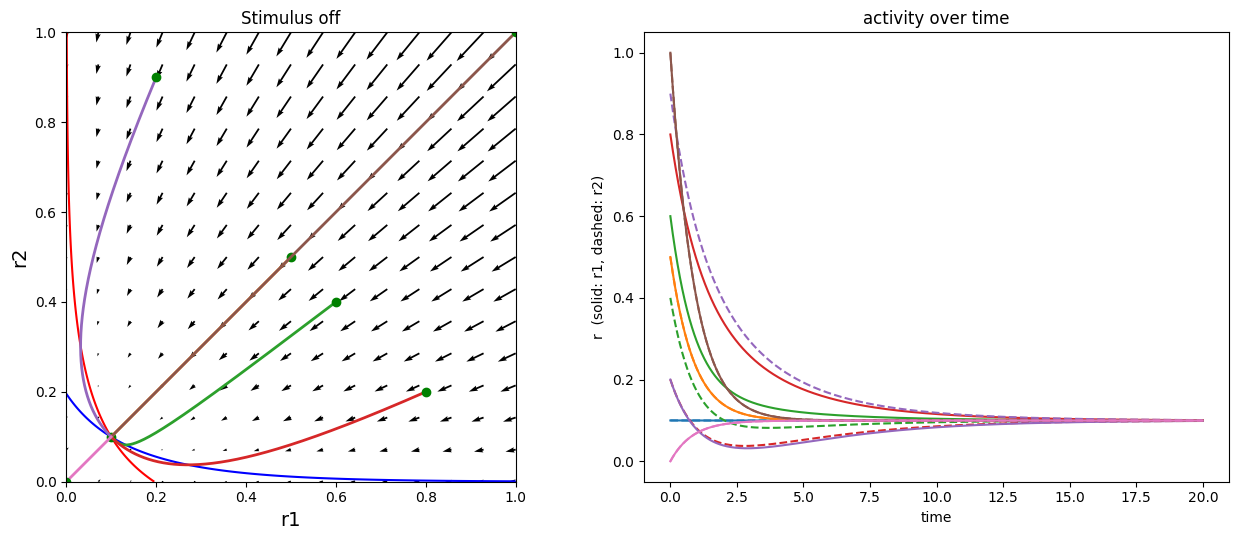

In [17]:
#My answer: Topic 4 (A)
plot_decision(np.array([0, 0]), 'Stimulus off', starts)

**My answer: Topic 4 (A)**

With no external stimulation applied, the dominating input for each neuron is the negative background input $I_{bg} = -2$, and the sigmoid remains in the low regime. The red ($\dot r_1 = 0$) and blue ($\dot r_2 = 0$) nullclines intersect **at only one point**, which is a low symmetric point $\mathbf{r^*} \approx (0.10,\,0.10)$. The vector field is pointing towards this point from any other point of the plane.

**Prediction:** both neurons end up with a low baseline of activity independently of their initial values; no neuron wins.

**Simulation:** all initial conditions lead to the convergence to a single low point $(0.10,\,0.10)$ regardless whether one of the neurons is initially very active (for example, initial condition $(0.8,\, 0.2)$ or $(1,\,1)$).

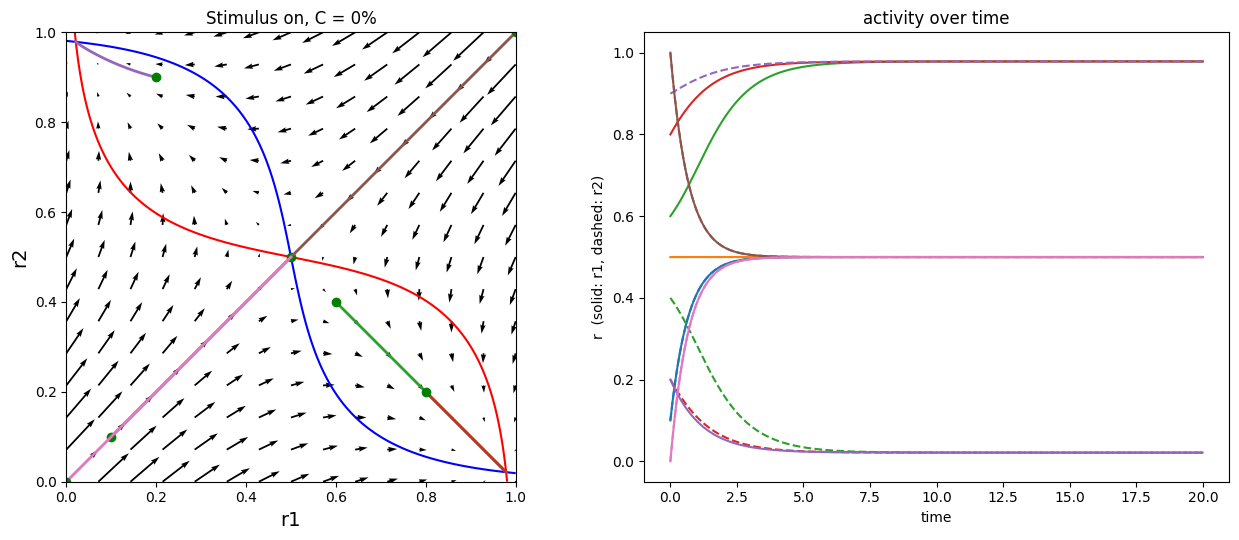

In [19]:
# My answer: Topic 4 (B)
plot_decision(stim(0), 'Stimulus on, C = 0%', starts)

**Topic 4 (B)**

At $C = 0\%$, both neurons get the same additional input $I_1 = I_2 = 3$. The nullclines change their shape and cross each other **three times**:

* at the point with a high $r_1$, low $r_2$: $(0.98, 0.02)$,
* at the point with a low $r_1$, high $r_2$: $(0.02, 0.98)$,
* at the symmetric point: $(0.5, 0.5)$.

The phase plane is symmetric about the line $r_1 = r_2$. The two extreme points are attractors, whereas the center one is an attractor along the diagonal, but is a saddle point in the perpendicular direction. The diagonal is the boundary between the two scenarios.

**Prediction:** the neurons become asymmetric with one neuron being active while the other is suppressed (winner take all), and it depends only on which side of the diagonal does the trajectory begin.

**Simulation:** begins under the diagonal $(r_1 > r_2$ e.g. $(0.6, 0.4)$, $(0.8, 0.2))$ ending up to $(0.98, 0.02);$ begins over the diagonal $(r_2 > r_1$ e.g. $(0.2, 0.9))$ ending up to $(0.02, 0.98)$. Beginning exactly on the diagonal line including the rest point $(0.1, 0.1)$ follows symmetric trajectories until arriving at the saddle point $(0.5, 0.5).$

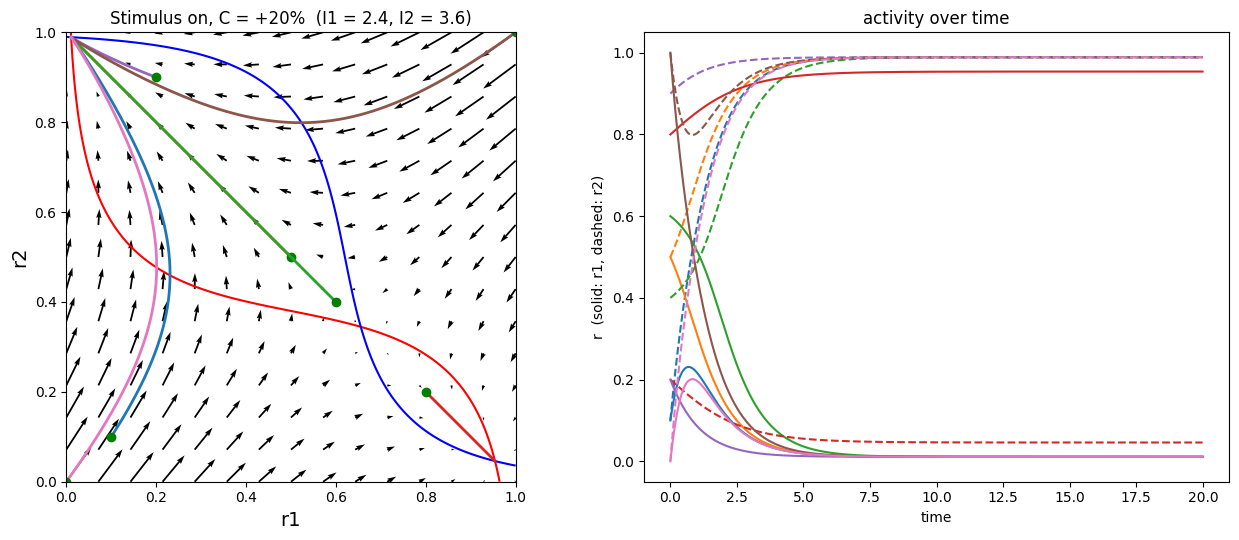

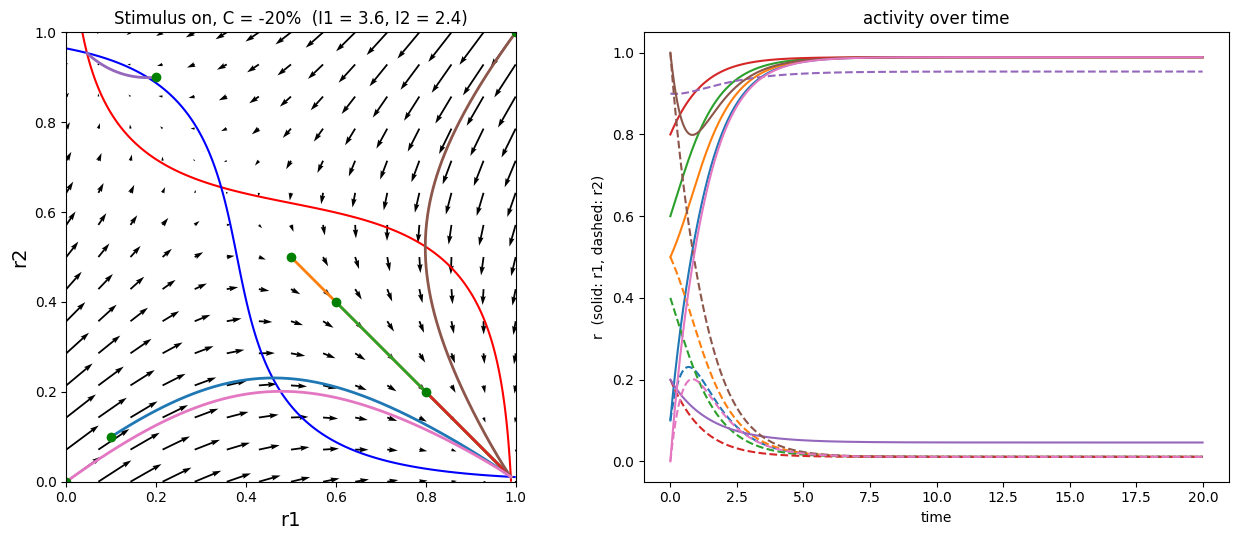

In [20]:
#My answer: Topic 4 (C)
plot_decision(stim(20), 'Stimulus on, C = +20%  (I1 = 2.4, I2 = 3.6)', starts)
plot_decision(stim(-20), 'Stimulus on, C = -20%  (I1 = 3.6, I2 = 2.4)', starts)

**My answer: Topic 4 (C)**

Note: with the given formulas, $C > 0$ favors neuron 2 with more input ($I_2 > I_1$), while $C < 0$ favors neuron 1.

For $C = 20\%$ ($I_1 = 2.4$, $I_2 = 3.6$), the phase plane gets an asymmetry. There are still three crossing points, however, the saddle point shifts away from the diagonal to the neuron 1 side up to $(0.66, 0.34)$. Hence, the basin of attraction of the favored state $(0.01,\, 0.99)$ becomes much larger compared to the basin of the other state $(0.95,\, 0.05)$. For $C = -20\%$, the picture is symmetric to the case for $C = 20\%$.

**Prediction:** out of rest, the neuron that has more input is going to be the winner. But only in those instances where the other neuron wants to win will win.
**Simulation ($C = 20\%$):** starting from rest $(0.1,\, 0.1)$, diagonal $(0.5, 0.5)$ and even $(0.6, 0.4)$, the system ends up with $(0.01,\, 0.99)$, i.e. the neuron 2 wins. Only the biased start $(0.8,\, 0.2)$ leads to $(0.95,\, 0.05)$. For $C = -20\%$, the same starts end up with the neuron 1 winning at $(0.99,\, 0.01)$.

**My answer: Topic 4 (D)**

The system's decision is made by a reorganization of its phase plane configuration:

1. **Prior to the stimulus activation** there is only one stable, low, symmetric state $(0.1,\,0.1)$: the network remains idle without any preference for one choice over the other.
2. **Upon activation of the stimulus**, the additional influence leads to the situation when self excitation ($+3$) and mutual inhibition ($-5$) are prevailing. The unique fixed point is replaced by **two stable states** (one for each choice) separated by a **saddle**. The previously existing equilibrium point is now placed inside the basin of attraction of one of them.
3. **The coherence determines which basin of attraction it is.** The bias due to net flow direction displaces the saddle point and the corresponding basin boundary so that the original equilibrium is moved to the basin of attraction of the neuron receiving the larger input.
4. **Winner takes all:** as the preferred neuron fires more often, its inhibitory effect on its competitor becomes stronger, whereas the feedback inhibition that it gets becomes weaker, thus amplifying a slight difference in inputs to a winner-take-all situation.
5. **Commitment:** once the attractor is reached, the system stays within it, thus ensuring stability and discreteness of the decision-making process. The time spent by the system near the saddle point indicates deliberation, the more coherent the trajectory ($|C|$ is larger), the faster the decision.

The winning neuron becomes the direction chosen by the model.

**My answer: Topic 4 (E)**

With $C = 0\%$, the input to the neurons is exactly equal and the system has perfect symmetry; the stimulus does not have a preference for any neuron. This is settled by the **initial conditions**: whether it lies on one side of the diagonal line $r_1 = r_2$ (basically which basin it is in). Whatever neuron is more active initially, wins because of the saddle.

If it happens that the network starts in a perfectly symmetrical state (like at rest) then it will be on the diagonal line and the final state of the network will also be the saddle, hence no decision is reached. This is however in an ideal situation; in reality this symmetry is broken because of fluctuations.

**Answer: Topic 4 (F)**

With high levels of noise, the trajectories will be kicked randomly:

* **When $C = 0\%$:** the symmetry is destroyed by noise, so the network comes to a decision anyway, but it is random, i.e., about 50/50.
* **With low coherence values:** the noise may drive the trajectory past the boundary of the shifted basin of attraction, so the model will make mistakes from time to time. The errors become less frequent with higher values of $|C|$, so we obtain the psychometric curve similar to that of real subjects.
* **Decision time:** the duration of the approach to the saddle is no longer fixed; therefore, there will be a distribution of reaction times.
* **High noise levels:** may drive the network away from its state of decision-making, leading to a change of mind or instability of decision-making.

So noise transforms our model into a probabilistic decision-making one.

In [22]:
# My answer: Topic 4 (G)
def jacobian(r, par):
    '''J = -I + diag(g'(x)) W, with x = W r + I_bg + I_stim.'''
    x = par[0] @ r + par[1] + par[2]
    gp = g(x) * (1 - g(x))
    return -np.eye(2) + gp[:, None] * par[0]
def classify(eigs):
    re, im = np.real(eigs), np.imag(eigs)
    if np.any(np.abs(im) > 1e-9):
        return 'stable focus' if np.all(re < 0) else 'unstable focus'
    if np.all(re < 0): return 'stable node'
    if np.all(re > 0): return 'unstable node'
    return 'saddle (unstable)'
def find_fixed_points(par, n=21):
    fps = []
    for a in np.linspace(0, 1, n):
        for b in np.linspace(0, 1, n):
            sol, info, ier, msg = fsolve(f, [a, b], args=(par,), full_output=True)
            if ier == 1 and not any(np.allclose(sol, p, atol=1e-5) for p in fps):
                fps.append(sol)
    return fps

for name, I_stim in [('Stimulus off', np.array([0, 0])), ('Stimulus on, C = 20%', stim(20))]:
    par = [W, I_bg, I_stim]
    print(name)
    for fp in find_fixed_points(par):
        eigs = np.linalg.eigvals(jacobian(fp, par))
        print(f'  r* = {np.round(fp, 3)},  eigenvalues = {np.round(eigs, 3)},  {classify(eigs)}')

Stimulus off
  r* = [0.1 0.1],  eigenvalues = [-0.281 -1.18 ],  stable node
Stimulus on, C = 20%
  r* = [0.655 0.345],  eigenvalues = [ 0.807 -1.452],  saddle (unstable)
  r* = [0.954 0.046],  eigenvalues = [-0.649 -1.088],  stable node
  r* = [0.011 0.989],  eigenvalues = [-0.914 -1.021],  stable node


**My answer: Topic 4 (G)**

Since the system is nonlinear, the fixed points are found numerically (`fsolve` from a grid of initial guesses), and their types determined based on the eigenvalues of the Jacobian

$$
J(\mathbf r^*) = -I + \mathrm{diag}\big(g'(\mathbf x^*)\big)\,W, \qquad \mathbf x^* = W\mathbf r^* + I_{bg} + \mathbf I_{stim}, \qquad g'(x) = g(x)\big(1 - g(x)\big)
$$

| Condition | Fixed point $\mathbf r^*$ | Eigenvalues | Type |
|---|---|---|---|
| No stimulus | $(0.100,\ 0.100)$ | $-0.28,\ -1.18$ | stable node |
| $C = 20\%$ | $(0.011,\ 0.989)$ | $-0.91,\ -1.02$ | stable node (neuron 2 wins) |
| $C = 20\%$ | $(0.954,\ 0.046)$ | $-0.65,\ -1.09$ | stable node (neuron 1 wins) |
| $C = 20\%$ | $(0.655,\ 0.345)$ | $+0.81,\ -1.45$ | saddle (unstable) |

**Interpretation.** If the stimulus is not present, the system has one stable node – the low resting state. When the stimulus is present, the system is bistable: two stable nodes (corresponding to the two decisions) and a saddle that separates them; the stable direction of the saddle determines the border of the basins. At $C = 20\%$, the saddle is positioned on the neuron 1 side, and thus the attractor that is most likely to win (neuron 2 wins) will have the larger basin of attraction. The basins of attraction are such that the resting point $(0.1, 0.1)$ is attracted to the winning attractor. There are no oscillations because all the eigenvalues are real.

### Exam example question (not graded)
In all of the above, anything that can be done mathematically would be expected to be done during the pen and paper exam. Anythign that had to be simulated could be expected to be intuitively reproduced, if not exactly. Here follows an example question that builds on the final assignment, but note that completely never seen before model systems could be presented --- you need to understand dynamical systems of this type in general not just the wilson cowan model above. It is also a question with intuition based questions, but you should also expect questions of the same type that require more die-hard math ---- e.g. classify a fixed point mathematically, derive the nullclines, sketch the behevior of a system across time given the phase plots, etc.

<center><img src='./Exam_question.png' width=1200>

Source: a past exam